# E09 · Maxwell on a grid

Solve Maxwell’s coupled field equations with staggered samples, then find out why time steps, pixels, and computational boundaries are part of the physics calculation.

<!-- course-preparation:start -->
## Before this lab

Use these focused refreshers if an idea is unfamiliar; you do not need to complete each linked course.

- **Coupled electric and magnetic fields:** Recognize the coupling between changing electric and magnetic fields. Used here: The solver advances both fields in alternating updates. [Review: OpenStax · University Physics Volume 2, §16.1](https://openstax.org/books/university-physics-volume-2/pages/16-1-maxwells-equations-and-electromagnetic-waves). Read Maxwell's Equations and the discussion connecting changing electric and magnetic fields. Concentrate on Faraday's and Ampère–Maxwell's laws.
- **Derivatives on a sampled grid:** Approximate a derivative with neighboring samples and read partial derivatives as local rates of change. Used here: The Yee grid replaces spatial and temporal derivatives by staggered differences. [Review: MIT OCW · Lecture 10: Finite Differences in Time](https://ocw.mit.edu/courses/18-085-computational-science-and-engineering-i-fall-2008/resources/lecture-10-finite-differences-in-time/). Focus on replacing a derivative by a difference quotient and taking successive Euler steps. The stability discussion gives useful context for E09.

**Python preparation:** Use neighboring array slices and a time loop; distinguish field samples, probes, and recorded traces.
- [NumPy · The absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html) — Use the sections on array shape, indexing and slicing, basic operations, and broadcasting. Practice changing one parameter and rerunning a cell.

**Developed here:** Construct a Yee update, test its time-step limit, and measure boundary reflections and PML performance.

[All prerequisites and learning resources](https://vandermode.github.io/optics-in-5-minutes-course/preparation/)
<!-- course-preparation:end -->

**Core lab: 25–30 minutes.** Work through the predictions before running the next cell. Sections labelled optional can be skipped on a first pass. Run all executes both the core and the small CPU extension.

**You will learn to:**

- Explain the spatial and temporal staggering of a Yee update.
- Distinguish instability, numerical dispersion, and boundary reflection.
- Measure reflection with a reference run and verify an absorber by refinement.

**Model:** 1D normalized Yee fields with real, nondispersive ε = n² and μ = 1. The PML specialization uses cubic grading with κ = 1 and α = 0. The electric source is bidirectional. The field display clips amplitudes outside ±1; the growth plot reports actual maxima and stops at 10⁶.

This notebook is self-contained. It uses synthetic data, runs on CPU, and needs no repository clone, mounted Drive, API key, or external dataset. The setup installs only missing packages. Figures are displayed as static PNGs and also saved in a local folder for download.


In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ["numpy", "scipy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
FIGURES = Path("e09_figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": False, "figure.constrained_layout.use": True})
def show(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)


Python 3.12.13 | NumPy 2.4.3 | SciPy 1.16.3 | Matplotlib 3.11.2


## 1 · Stagger the fields in space and time

We use normalized c=ε₀=μ₀=1 and vacuum wavelength 1. Ez lives on integer cells;
Hy is shifted half a cell and half a time step. With our sign convention a right-going
wave has Hy=-n Ez. Update H from differences of E, then E from differences of H.
The 1D Courant number is S=dt/dx and must not exceed 1 in vacuum.

The boundary uses convolutional PML auxiliary memories. Defaults κ=1 and α=0 give
a simple graded coordinate stretch; the function exposes κ and α for extensions.
A layer that damps only E is also supplied for comparison—it is not a matched PML.
**Predict:** can a better absorbing boundary repair a time step above the CFL limit?

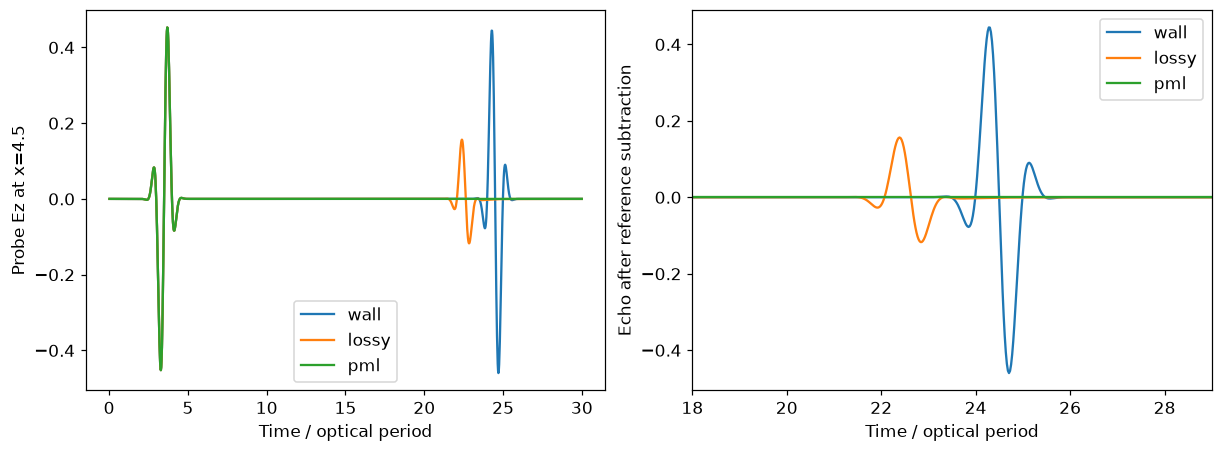

Late-window squared-field ratios: {'wall': np.float64(1.0000000000000104), 'lossy': np.float64(0.10308107557771648), 'pml': np.float64(1.0304947210987933e-14)}


In [2]:
def cpml(positions, end, pml_cells, dx, dt, left=True, right=True, m=3, target=1e-7, kappa_max=1., alpha_max=0.):
    positions = np.asarray(positions, float)
    if not pml_cells:
        return np.ones_like(positions), np.zeros_like(positions), np.ones_like(positions)
    depth = np.zeros_like(positions)
    if left:
        depth = np.maximum(depth, pml_cells - positions)
    if right:
        depth = np.maximum(depth, positions - (end - pml_cells))
    u = np.clip(depth / pml_cells, 0, 1)
    sigma_max = -(m + 1) * np.log(target) / (2 * pml_cells * dx)
    sigma = sigma_max * u**m
    kappa = 1 + (kappa_max - 1) * u**m
    alpha = alpha_max * (1 - u) * (u > 0)
    b = np.exp(-(sigma / kappa + alpha) * dt)
    a = np.zeros_like(b)
    np.divide(sigma * (b - 1), kappa * (sigma + kappa * alpha), out=a, where=sigma > 0)
    return b, a, kappa


def run1d(nx=601, N=40, S=.9, pml_cells=40, right='pml', eps=None, time=30, probes=(180,), src=120, t0=2., tau=.5, f0=1., initial=None, alpha=0., kappa=1.):
    dx = 1 / N
    dt = S * dx
    steps = round(time / dt)
    eps = np.ones(nx) if eps is None else np.asarray(eps)
    E, H = np.zeros(nx), np.zeros(nx - 1)
    if initial is not None:
        E[:], H[:] = initial
    ph, pe = np.zeros(nx - 1), np.zeros(nx - 2)
    bh, ah, kh = cpml(np.arange(nx - 1) + .5, nx - 1, pml_cells, dx, dt, right=right=='pml', alpha_max=alpha, kappa_max=kappa)
    be, ae, ke = cpml(np.arange(1, nx - 1), nx - 1, pml_cells, dx, dt, right=right=='pml', alpha_max=alpha, kappa_max=kappa)
    sigma = np.zeros(nx)
    if right == 'lossy':
        sigma[nx - 1 - pml_cells:] = 10.
    q = sigma * dt / (2 * eps)
    ca = (1 - q) / (1 + q)
    cb = dt / (dx * eps * (1 + q))
    tr = np.empty((steps, len(probes)))
    maxima = np.empty(steps)
    energy = np.empty(steps)
    flux = np.empty_like(tr)
    for k in range(steps):
        old_probe = E[list(probes)].copy()
        de = E[1:] - E[:-1]
        ph = bh * ph + ah * de
        H += S * (de / kh + ph)
        dh = H[1:] - H[:-1]
        pe = be * pe + ae * dh
        E[1:-1] = ca[1:-1] * E[1:-1] + cb[1:-1] * (dh / ke + pe)
        if src is not None:
            t = (k + 1) * dt
            E[src] += np.exp(-((t-t0)/tau)**2) * np.sin(2*np.pi*f0*(t-t0))
        E[0] = E[-1] = 0.
        tr[k] = E[list(probes)]
        pp = np.asarray(probes)
        flux[k] = -.25 * (old_probe + E[pp]) * (H[pp - 1] + H[pp])
        maxima[k] = np.max(abs(E))
        energy[k] = .5 * dx * (np.sum(eps * E**2) + np.sum(H**2))
    return np.arange(1, steps + 1) * dt, tr, maxima, energy, flux



N=40;nx=15*N+1
# A longer vacuum reference keeps its far-wall echo outside our recording window.
t,reference,_,_,_=run1d(nx=1001)
incident=(t>1)&(t<6);late=(t>18)&(t<29)
incident_norm=np.sum(reference[incident,0]**2)
fig,ax=plt.subplots(1,2,figsize=(11,4))
boundary_errors={}
for boundary in ['wall','lossy','pml']:
    _,trace,maxima,energy,_=run1d(right=boundary)
    difference=trace[:,0]-reference[:,0]
    ratio=np.sum(difference[late]**2)/incident_norm
    boundary_errors[boundary]=ratio
    ax[0].plot(t,trace[:,0],label=boundary)
    ax[1].plot(t,difference,label=boundary)
ax[0].set(xlabel="Time / optical period",ylabel="Probe Ez at x=4.5")
ax[1].set(xlim=(18,29),xlabel="Time / optical period",ylabel="Echo after reference subtraction")
for a in ax:a.legend()
show(fig,"01-boundary-reflections")
assert boundary_errors['pml']<1e-5 and boundary_errors['pml']<boundary_errors['lossy']
print("Late-window squared-field ratios:",boundary_errors)

## 2 · Measure a dielectric reflection, not a raw probe peak

Run a vacuum reference, subtract its field to isolate the reflected pulse, and gate the
arrivals before boundary echoes return. At normal incidence, R=((1-n₂)/(1+n₂))².
T needs the n₂/n₁ flux factor. For a broad pulse, finite-grid dispersion and temporal
gating make this an approximation. The solver also returns interpolated -E×H flux.

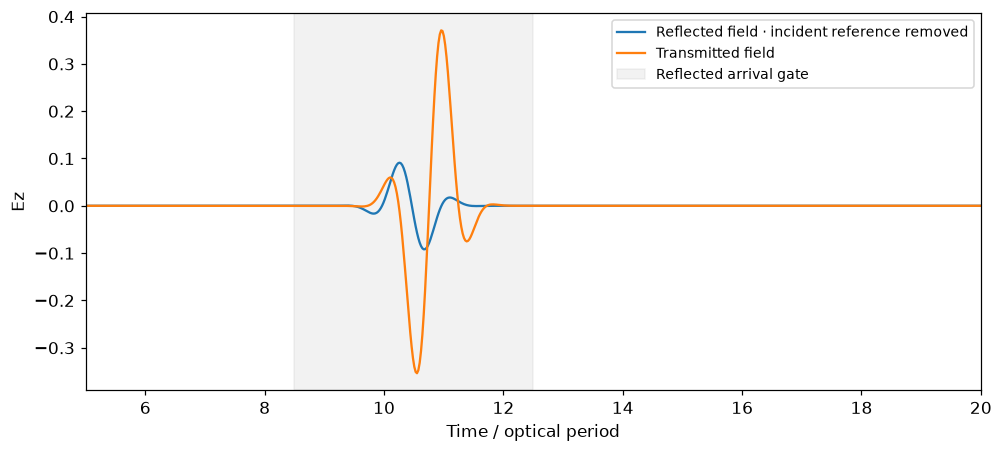

R=0.040838, analytic R=0.040000; T amplitude estimate=0.963334; T flux=0.959164


In [3]:
n2=1.5;eps=np.ones(nx);eps[8*N:]=n2*n2
_,tr,_,_,flux=run1d(eps=eps,probes=(180,420))
_,ref,_,_,refflux=run1d(nx=1001,probes=(180,420))
rgate=abs(t-10.5)<2;tgate=abs(t-(7+2.5*n2))<2
R=np.sum((tr[rgate,0]-ref[rgate,0])**2)/incident_norm
T=n2*np.sum(tr[tgate,1]**2)/incident_norm
Tflux=np.sum(flux[tgate,1])/np.sum(refflux[incident,0])
exact=((1-n2)/(1+n2))**2
assert abs(R-exact)<.002 and abs(R+T-1)<.015
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(t,tr[:,0]-ref[:,0],label="Reflected field · incident reference removed")
ax.plot(t,tr[:,1],label="Transmitted field")
ax.axvspan(8.5,12.5,alpha=.1,color="gray",label="Reflected arrival gate")
ax.set(xlim=(5,20),xlabel="Time / optical period",ylabel="Ez");ax.legend(fontsize=9)
show(fig,"02-interface-reflection")
print(f"R={R:.6f}, analytic R={exact:.6f}; T amplitude estimate={T:.6f}; T flux={Tflux:.6f}")

## 3 · Stability and accuracy answer different questions

A stable grid can still give the wrong phase velocity. In 1D vacuum the Yee relation is
sin(ωdt/2)=S sin(knum dx/2). More cells per wavelength reduce dispersion.
A dielectric has a shorter wavelength: count its cells using λ₀/n, not λ₀ alone.
Boundary refinement must be tested while holding physical PML thickness fixed.

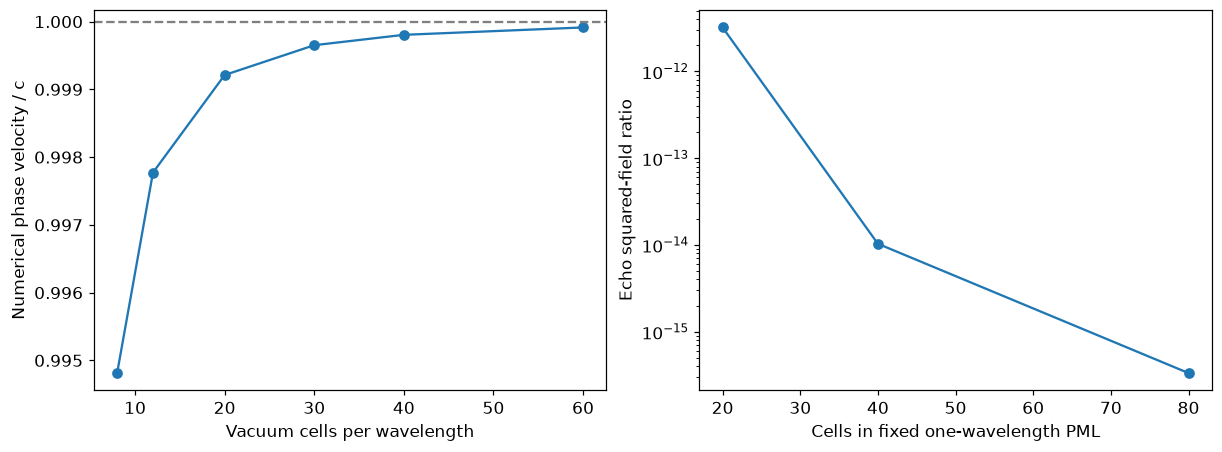

PML refinement: [np.float64(3.1978058370689562e-12), np.float64(1.0304947210987933e-14), np.float64(3.3419150612414285e-16)]
Courant 0.9 max field after 200 steps 0.5004779805935318
Courant 1.02 max field after 200 steps 1.4736907905262167e+23


In [4]:
resolutions=np.array([8,12,20,30,40,60])
S=.9
kd=2*np.arcsin(np.sin(np.pi*S/resolutions)/S)
velocity=2*np.pi/(resolutions*kd)
assert abs(velocity[-1]-1)<abs(velocity[0]-1)
absorber=[]
for resolution in [20,40,80]:
    count=15*resolution+1;probe=round(4.5*resolution)
    tt,small,_,_,_=run1d(nx=count,N=resolution,pml_cells=resolution,probes=(probe,),src=3*resolution)
    _,large,_,_,_=run1d(nx=25*resolution+1,N=resolution,pml_cells=resolution,probes=(probe,),src=3*resolution)
    incoming=(tt>1)&(tt<6);echo=(tt>18)&(tt<29)
    absorber.append(np.sum((small[echo,0]-large[echo,0])**2)/np.sum(large[incoming,0]**2))
assert absorber[-1]<absorber[0]
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(resolutions,velocity,"o-");ax[0].axhline(1,color="gray",ls="--")
ax[0].set(xlabel="Vacuum cells per wavelength",ylabel="Numerical phase velocity / c")
ax[1].semilogy([20,40,80],absorber,"o-")
ax[1].set(xlabel="Cells in fixed one-wavelength PML",ylabel="Echo squared-field ratio")
show(fig,"03-grid-and-absorber-convergence")
print("PML refinement:",absorber)
for S in [.9,1.02]:
    cells=241;j=np.arange(cells)
    initial=(np.exp(-((j-80)/9)**2)+1e-12*(-1.)**j,np.zeros(cells-1))
    _,_,maximum,_,_=run1d(nx=cells,N=20,S=S,pml_cells=0,right='wall',time=200*S/20,src=None,initial=initial)
    print("Courant",S,"max field after 200 steps",maximum[-1])
    assert maximum[-1]<2 if S<1 else maximum[-1]>1e10

## Optional extension · A 2D TMz grid with CPML

Ez is surrounded by staggered Hx and Hy. Each derivative direction needs its own PML
memory. On an equal-spacing vacuum grid the stability bound is now S≤1/√2.
The pulse and large-domain reference use identical source and probe positions relative
to the center. Their difference isolates finite-boundary errors.

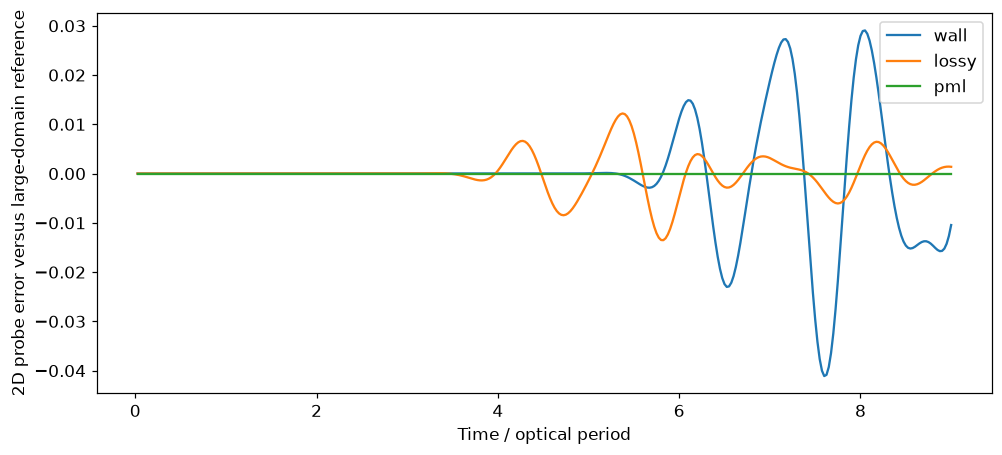

2D boundary squared-field ratios: {'wall': np.float64(1.2460304347578022), 'lossy': np.float64(0.15606143619535326), 'pml': np.float64(5.569524361758012e-12)}


In [5]:
def run2d(nx=121, ny=121, N=20, S=.5, pml_cells=20, boundary='pml', time=9, probe_offset=(20,0), eps=None, initial=None, source=True):
    dx, dt=1/N, S/N
    steps=round(time/dt)
    E=np.zeros((nx,ny))
    Hx=np.zeros((nx,ny-1))
    Hy=np.zeros((nx-1,ny))
    if initial is not None:
        E[:]=initial
    eps=np.ones_like(E) if eps is None else np.asarray(eps)
    pxh,pyh=np.zeros_like(Hy),np.zeros_like(Hx)
    pxe,pye=np.zeros((nx-2,ny-2)),np.zeros((nx-2,ny-2))
    P=pml_cells if boundary=='pml' else 0
    bxh,axh,kxh=cpml(np.arange(nx-1)+.5,nx-1,P,dx,dt)
    byh,ayh,kyh=cpml(np.arange(ny-1)+.5,ny-1,P,dx,dt)
    bxe,axe,kxe=cpml(np.arange(1,nx-1),nx-1,P,dx,dt)
    bye,aye,kye=cpml(np.arange(1,ny-1),ny-1,P,dx,dt)
    sig=np.zeros_like(E)
    if boundary=='lossy':
        sig[:pml_cells,:]=sig[-pml_cells:,:]=10
        sig[:,:pml_cells]=sig[:,-pml_cells:]=10
    q=sig*dt/(2*eps)
    ca=(1-q)/(1+q)
    cb=dt/(dx*eps*(1+q))
    center=(nx//2,ny//2)
    probe=(center[0]+probe_offset[0],center[1]+probe_offset[1])
    traces=np.empty(steps)
    maxima=np.empty(steps)
    for n in range(steps):
        dex=E[1:,:]-E[:-1,:]
        dey=E[:,1:]-E[:,:-1]
        pxh=bxh[:,None]*pxh+axh[:,None]*dex
        pyh=byh[None,:]*pyh+ayh[None,:]*dey
        Hy+=S*(dex/kxh[:,None]+pxh)
        Hx-=S*(dey/kyh[None,:]+pyh)
        dhy=Hy[1:,1:-1]-Hy[:-1,1:-1]
        dhx=Hx[1:-1,1:]-Hx[1:-1,:-1]
        pxe=bxe[:,None]*pxe+axe[:,None]*dhy
        pye=bye[None,:]*pye+aye[None,:]*dhx
        E[1:-1,1:-1]=ca[1:-1,1:-1]*E[1:-1,1:-1]+cb[1:-1,1:-1]*(dhy/kxe[:,None]+pxe-dhx/kye[None,:]-pye)
        if source:
            t=(n+1)*dt
            E[center]+=np.exp(-((t-1.4)/.55)**2)*np.sin(2*np.pi*(t-1.4))
        E[0,:]=E[-1,:]=E[:,0]=E[:,-1]=0
        traces[n]=E[probe]
        maxima[n]=abs(E).max()
    return (np.arange(steps)+1)*dt,traces,maxima



t2,large,_=run2d(nx=321,ny=321,pml_cells=0,boundary='wall')
fig,ax=plt.subplots(figsize=(9,4))
errors={}
for boundary in ['wall','lossy','pml']:
    _,trace,_=run2d(boundary=boundary)
    delta=trace-large
    errors[boundary]=np.sum(delta[t2>4]**2)/np.sum(large[t2<4]**2)
    ax.plot(t2,delta,label=boundary)
ax.set(xlabel="Time / optical period",ylabel="2D probe error versus large-domain reference");ax.legend()
show(fig,"04-2d-cpml")
assert errors['pml']<errors['lossy'] and errors['pml']<1e-4
print("2D boundary squared-field ratios:",errors)

## A short lab report

**1. Measure an interface.** Estimate reflectance for n: 1 → 1.5 with a reference-subtracted, time-gated trace.

**2. Audit the boundary.** Compare wall, loss layer, and CPML with identical excitation and a larger-domain reference.

**3. Separate two failures.** Create a stable coarse run and an unstable fine run, then explain why each is unreliable.

### Worked reasoning

**Measure an interface.** Compare with ((1−1.5)/(1+1.5))² = 0.04, then refine the grid. Keep incident normalization and arrival windows fixed physically.

**Audit the boundary.** Subtract fields before squaring. Distinguish amplitude echo ratios from integrated reflected-power estimates.

**Separate two failures.** The first can accumulate dispersion error; the second violates the time-step stability bound. Refining space without reducing Δt can make stability worse.

### Ten-point rubric

Prediction and reasoning: 2; reproducible parameters, units, and plots: 3; quantitative validation: 3; limitations and interpretation: 2.

## References

- [Meep · Introduction and Courant stability](https://meep.readthedocs.io/en/stable/Introduction/)
- [Meep · Perfectly matched layers and convergence](https://meep.readthedocs.io/en/latest/Perfectly_Matched_Layer/)
- [Roden & Gedney · Convolution PML](https://doi.org/10.1002/1098-2760(20001205)27:5%3C334::AID-MOP14%3E3.0.CO;2-A)

## Save your figures

The final cell creates a ZIP of the computed PNGs. In Colab, use the Files sidebar to download it if an output frame or link is blocked. Saved notebook outputs and the public lesson's figure download provide another viewing route.

In [6]:
import zipfile
archive = FIGURES.with_suffix(".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(FIGURES.glob("*.png")):
        bundle.write(file, file.name)
print("Saved", len(list(FIGURES.glob("*.png"))), "figures in", archive)
display(FileLink(str(archive)))


Saved 4 figures in e09_figures.zip


/tmp/optics-notebooks-xppq4daw/E09/e09_figures.zip